# La joroba de capacidad: cómo la velocidad de un cono secundario fija su tonelaje, su potencia y su producto

**Pregunta:** ¿A qué velocidad excéntrica mueve más toneladas por hora el cono secundario de referencia, y qué cuesta en potencia y en tamaño de producto alejarse de esa velocidad?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 03-breakage-and-classification
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook usted puede:

- escribir la ley de capacidad reducida del motor y decir qué hace su factor de velocidad;
- encontrar la velocidad de capacidad máxima de cada tipo de máquina y mostrar que todas comparten una curva normalizada;
- ejecutar el motor en un rango de velocidades y leer juntos la capacidad, la potencia y el tamaño del producto;
- leer el ángulo de apriete frente a su límite de agarre y decir qué le hace una abertura más ancha.

## Preparación

Numpy y matplotlib. Las funciones de capacidad y de apriete vienen directamente del módulo de capacidad del motor.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda importa la ley de capacidad, la velocidad óptima, la geometría de apriete y la tabla de máquinas, junto al motor.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.capacity import CAP, nip_angle, nip_limit, optimal_speed, throughput
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El cono secundario de referencia S01 (CSS 32 mm, carrera 30 mm, 360 rpm). Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee el punto de operación.

In [2]:
# Lea el punto de operación de S01
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
op = Operating(**manifest["params"])
print(op)

Operating(machine='cone-sec', css_mm=32.0, throw_mm=30.0, speed_rpm=360.0, feed_x63_mm=90.0, feed_m=1.2, ore_axb=55.0, ore_wi=14.0, calibrated=False)


## Método

**Paso 1, la ley.** El motor usa una forma reducida del modelo de flujo de chancadores de cono de Evertsson (Evertsson, 2000; https://research.chalmers.se/en/publication/759), con números absolutos que son referencias ilustrativas por máquina:

$$Q = Q_{ref}\;\frac{CSS + T/2}{g_{ref}}\;s\,e^{1-s}, \qquad s = \frac{\text{velocidad}}{\text{velocidad}_{opt}}$$

El primer factor es la apertura de descarga, la abertura media $CSS + T/2$ sobre una abertura de referencia, de modo que la capacidad crece linealmente con la apertura. El segundo es la joroba de capacidad: $s\,e^{1-s}$ vale 1 en $s = 1$ y cae a ambos lados. A baja velocidad la cámara descarga lentamente; pasado el óptimo la cabeza giratoria obstruye la caída libre del material más rápido de lo que la gravedad lo despeja. La celda lee las tres constantes de la máquina de S01 y la velocidad óptima.

In [3]:
# Constantes de la ley de capacidad de la máquina de S01, y su velocidad óptima
model = CAP[op.machine]
at_s01 = throughput(op.machine, op.css_mm, op.throw_mm, op.speed_rpm)
print("capacidad de referencia [t/h]:", model.q_ref, "| velocidad óptima [rpm]:", optimal_speed(op.machine),
      "| abertura de referencia [mm]:", model.ref_gap_mm)
print("capacidad en S01 [t/h]:", round(at_s01, 2))

capacidad de referencia [t/h]: 520 | velocidad óptima [rpm]: 360 | abertura de referencia [mm]: 38
capacidad en S01 [t/h]: 643.16


**Paso 2, una curva para todas las máquinas.** Dividir la velocidad de cada máquina por su propio óptimo, y su capacidad por su capacidad en ese óptimo, debería colapsar los cinco tipos de máquina del motor en la única curva $s\,e^{1-s}$, porque entre ellas solo difieren $Q_{ref}$, la velocidad óptima y la abertura de referencia. La celda calcula las curvas normalizadas con la función del motor para cada máquina con su propia abertura de referencia, de modo que el primer factor vale 1, y la figura las superpone.

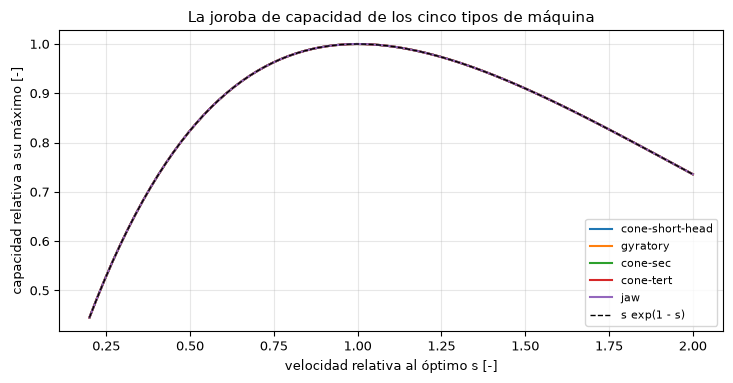

In [4]:
# Capacidad normalizada contra velocidad normalizada de los cinco tipos de máquina, con su abertura de referencia
s = np.linspace(0.2, 2.0, 80)
fig, ax = plt.subplots()
for machine, m in CAP.items():
    at_peak = throughput(machine, m.ref_gap_mm, 0.0, m.speed_opt)
    curve = [throughput(machine, m.ref_gap_mm, 0.0, v * m.speed_opt) / at_peak for v in s]
    ax.plot(s, curve, label=machine)
ax.plot(s, s * np.exp(1 - s), "k--", lw=1, label="s exp(1 - s)")
ax.set_xlabel("velocidad relativa al óptimo s [-]")
ax.set_ylabel("capacidad relativa a su máximo [-]")
ax.set_title("La joroba de capacidad de los cinco tipos de máquina")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las cinco líneas de colores quedan bajo la línea punteada: los tipos de máquina difieren en escala y en dónde alcanzan su máximo, no en la forma de la joroba. Esa forma la impone el motor: la ley de capacidad multiplica todas las máquinas por $s\,e^{1-s}$, de modo que la superposición confirma la implementación de la ley y no descubre una propiedad de chancadores reales. Un lector puede pasar de una máquina a otra sabiendo que la curva es la misma en el motor, y que la velocidad óptima es el número por máquina que importa. La figura muestra solo la capacidad; no dice nada de lo que paga el operador con una velocidad distinta del óptimo.

**Paso 3, la respuesta completa a la velocidad.** La velocidad también entra en la energía del apriete (notebook 01 del tema 03): un cono más rápido aplica más energía por apriete y quiebra más fino. La celda ejecuta todo el motor en S01 con cinco velocidades, desde la mitad hasta algo más de una vez y media el óptimo, e imprime capacidad, potencia y P80 de cada una. La figura dibuja las tres como porcentajes de su valor en el óptimo, para que sus unidades distintas compartan un eje.

In [5]:
# Ejecute el motor con cinco velocidades e imprima capacidad, potencia y P80
speeds = (180, 270, 360, 450, 560)
runs = {v: evaluate(replace(op, speed_rpm=float(v))) for v in speeds}
for v, r in runs.items():
    print(f"{v} rpm: {r.throughput_tph:6.1f} t/h  {r.power_kw:6.1f} kW  P80 {r.p80:5.2f} mm",
          f" Ecs {r.specific_energy_kwh_t:.3f} kWh/t")
loss = (1 - runs[560].throughput_tph / runs[360].throughput_tph) * 100
print(f"pérdida de capacidad a 560 rpm respecto del óptimo: {loss:.1f} %")

180 rpm:  530.2 t/h   219.2 kW  P80 30.04 mm  Ecs 0.509 kWh/t
270 rpm:  619.4 t/h   268.6 kW  P80 28.59 mm  Ecs 0.764 kWh/t
360 rpm:  643.2 t/h   287.4 kW  P80 27.70 mm  Ecs 1.018 kWh/t
450 rpm:  626.1 t/h   285.4 kW  P80 27.11 mm  Ecs 1.273 kWh/t
560 rpm:  574.0 t/h   264.0 kW  P80 26.85 mm  Ecs 1.584 kWh/t
pérdida de capacidad a 560 rpm respecto del óptimo: 10.7 %


La figura dibuja las tres salidas en una grilla más fina de 39 velocidades, cada una como porcentaje de su valor en el óptimo.

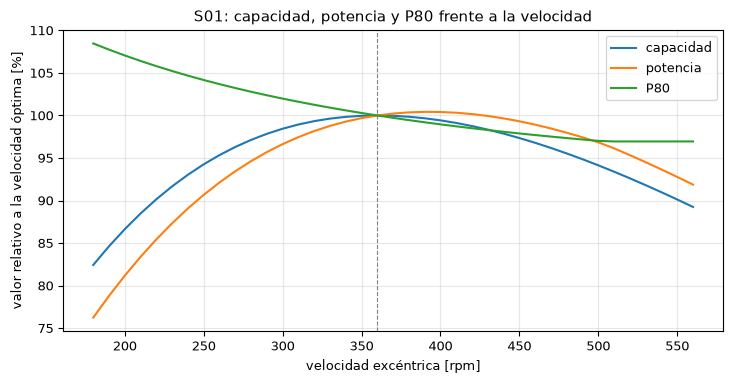

In [6]:
# Grafique capacidad, potencia y P80 como porcentajes de su valor en la velocidad óptima
grid = np.linspace(180, 560, 39)
curves = [evaluate(replace(op, speed_rpm=float(v))) for v in grid]
reference = evaluate(op)
fig, ax = plt.subplots()
ax.plot(grid, [r.throughput_tph / reference.throughput_tph * 100 for r in curves], label="capacidad")
ax.plot(grid, [r.power_kw / reference.power_kw * 100 for r in curves], label="potencia")
ax.plot(grid, [r.p80 / reference.p80 * 100 for r in curves], label="P80")
ax.axvline(optimal_speed(op.machine), color="grey", ls="--", lw=0.8)
ax.set_xlabel("velocidad excéntrica [rpm]")
ax.set_ylabel("valor relativo a la velocidad óptima [%]")
ax.set_title("S01: capacidad, potencia y P80 frente a la velocidad")
ax.legend()
fig.tight_layout()
plt.show()

Las tres curvas cuentan tres historias. La capacidad tiene su joroba y alcanza su máximo justo en la línea punteada de 360 rpm; la potencia sigue una curva más plana con su máximo cerca del óptimo (287 kW con 360 rpm, 285 kW con 450 rpm), porque una velocidad mayor compra más reducción mientras el tonelaje ya está bajando; y el P80 cae de manera constante con la velocidad, porque la energía por apriete sube. La velocidad que maximiza las toneladas no es entonces la que da el producto más fino, y el operador que quiere el producto más fino paga en capacidad. Lo que la figura no muestra es ningún límite de la máquina: el motor no modela desgaste de revestimientos ni vibración, y una velocidad muy sobre el rango de diseño no estaría permitida.

**Paso 4, el ángulo de apriete.** Una partícula es agarrada cuando el ángulo entre el manto y la taza es menor que el límite de agarre $2\arctan\mu$, con coeficiente de fricción $\mu = 0{,}35$, cerca de 38,6 grados (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). El ángulo de apriete del motor sube modestamente con la abertura, desde unos 22 grados para un cono con su abertura de referencia. La celda calcula el ángulo en un rango de aberturas frente al límite.

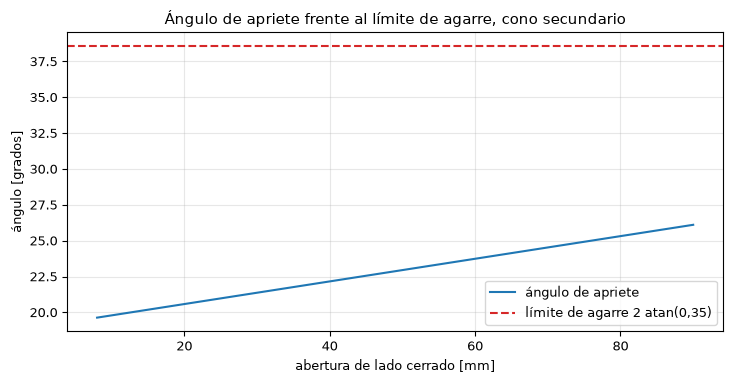

ángulo en S01: 21.53 | límite: 38.58 deg


In [7]:
# Ángulo de apriete del cono secundario frente a la abertura de lado cerrado, con el límite de agarre
settings = np.linspace(8, 90, 42)
angles = [nip_angle(op.machine, css) for css in settings]
fig, ax = plt.subplots()
ax.plot(settings, angles, label="ángulo de apriete")
ax.axhline(nip_limit(), color="tab:red", ls="--", label="límite de agarre 2 atan(0,35)")
ax.set_xlabel("abertura de lado cerrado [mm]")
ax.set_ylabel("ángulo [grados]")
ax.set_title("Ángulo de apriete frente al límite de agarre, cono secundario")
ax.legend()
fig.tight_layout()
plt.show()
print("ángulo en S01:", round(nip_angle(op.machine, op.css_mm), 2), "| límite:", round(nip_limit(), 2), "deg")

El ángulo se mantiene muy bajo el límite en todo el rango, en unos 21,5 grados para S01, de modo que con este modelo un cono secundario nunca pierde el agarre: no hay abertura en la que el motor prediga que las partículas resbalen. La figura también dice lo que no se modela: el ángulo es función solo de la abertura, sin dependencia de la forma de la partícula, del desgaste de revestimientos ni de la humedad de la alimentación, que son lo que en la práctica hace que un cono pierda agarre. La verificación es una cota de sensatez, no un predictor de deslizamiento.

## Resultados

**Respuesta:** el cono de referencia mueve más toneladas en su velocidad óptima de 360 rpm, 643,2 t/h, y pierde capacidad a ambos lados: 530,2 t/h con 180 rpm y 574,0 t/h con 560 rpm. Alejarse del óptimo cuesta distinto en cada sentido. Ir más rápido sube la energía por apriete de 1,018 a 1,584 kWh/t y baja el P80 de 27,70 a 26,85 mm, con una pérdida de tonelaje de 10,7 por ciento; ir más lento baja la potencia de 287 a 219 kW y engrosa el producto a 30,04 mm. El ángulo de apriete se mantiene cerca de 21,5 grados frente a un límite de 38,58.

La primera figura muestra que los cinco tipos de máquina del motor tienen la misma joroba, la segunda que capacidad, potencia y tamaño responden a la velocidad de tres maneras distintas, y la tercera que el agarre nunca es la restricción con este modelo. Un validador concluiría que la velocidad que maximiza el tonelaje es una propiedad de la máquina, y que elegir una velocidad es un compromiso entre toneladas, potencia y tamaño del producto, cuyos términos entrega el motor. Son números de forma reducida: los tonelajes absolutos son ilustrativos por tipo de máquina, y solo la vía real del HP500 del tema 05 los ancla a mediciones.

## Resumen

La capacidad es el producto de un factor de apertura lineal y una joroba en la velocidad que todos los tipos de máquina comparten. La velocidad mueve tres salidas de tres maneras distintas, así que la mejor velocidad depende de lo que le falte a la planta. El ángulo de apriete es una cota de sensatez, no un límite que se active. El notebook 02 aborda la abertura y la carrera y la energía de Bond detrás de la potencia.

## Referencias

- Evertsson, C. M. (2000), Cone crusher performance, doctoral thesis, Chalmers University of Technology. https://research.chalmers.se/en/publication/759
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193